# The Evolution of Tech Skills
CS 418 Fall 2026

**Data:** Hacker News monthly “Who is Hiring” threads. **Question:** How have requested tech skills changed, and what can job postings tell us about AI and entry-level roles?

**Limitations:** These posts are not a representative sample of the entire labor market; skill keyword mentions do not prove a skill is required.


In [1]:
from pathlib import Path
import pandas as pd
DATA_DIR = Path("../data/processed")
if not DATA_DIR.exists():
    DATA_DIR = Path("data/processed")
cleaned_df = pd.read_csv(DATA_DIR / "jobs_cleaned.csv")
analysis_df = pd.read_csv(DATA_DIR / "jobs_analysis.csv")
print("Cleaned posts:", len(cleaned_df))
print("Skill-analysis posts:", len(analysis_df))
display(cleaned_df.head())

Cleaned posts: 15197
Skill-analysis posts: 9124


,id,thread_id,date,year,month,company,role,location,remote,work_mode,salary,skills,skill_count,is_likely_job,text
0,34219342,34219335,2023-01-02 16:01:37+00:00,2023,1,Aha!,Rails / React / Devops,REMOTE,True,remote,NaN,"react, ruby, rails",3,True,Aha! ( https://www.aha.io ) | Rails / React / ...
1,34219356,34219335,2023-01-02 16:02:09+00:00,2023,1,Twaice,NaN,"Engineering, UX",True,remote,NaN,NaN,0,True,"Twaice | Engineering, UX | Munich, Germany or ..."
2,34219392,34219335,2023-01-02 16:04:17+00:00,2023,1,Symmetry Investments,Many Varied Roles,"REMOTE GLOBALLY or VISA (London, Hong Kong, Si...",True,remote,NaN,"python, typescript, rust, c++, git, linux",6,True,Symmetry Investments | Many Varied Roles | REM...
3,34219414,34219335,2023-01-02 16:05:35+00:00,2023,1,Source,NaN,San Francisco / Bay Area: Remote,True,remote,NaN,go,1,True,Source | San Francisco / Bay Area: Remote | Fu...
4,34219470,34219335,2023-01-02 16:08:43+00:00,2023,1,"Apple, Inc.",NaN,New York,False,unknown,NaN,NaN,0,True,"Apple, Inc. | New York | Cheltenham | Cupertin..."


In [2]:
print("Duplicate IDs:", cleaned_df["id"].duplicated().sum())
print("Years:", sorted(cleaned_df["year"].dropna().unique()))
display(cleaned_df.isna().sum().rename("Missing values"))

Duplicate IDs: 0
Years: [np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]


id                   0
thread_id            0
date                 0
year                 0
month                0
company           1229
role              5704
location          1649
remote               0
work_mode            0
salary           15197
skills            5603
skill_count          0
is_likely_job        0
text                 0
Name: Missing values, dtype: int64

## Changes since proposal

Our proposal considered hiring posts from 2011 onward. Our current dataset instead covers January 2023 through November 2026 (47 monthly threads), focusing on recent skill trends. The 2026 data is incomplete.

**Team to confirm:** Any other scope or modeling changes.

## Data preparation

We collected **15,252 raw Hacker News comments**, producing **15,197 unique cleaned records**. Our Python pipeline removed HTML formatting, extracted company, role, and location when possible, assigned heuristic work-mode labels, and detected mentions of **26 tracked technical skills**. A heuristic also flags likely hiring posts.

For skill analysis, we selected likely hiring posts mentioning at least one tracked skill: **9,124 posts**. We retain the full cleaned dataset for analyses requiring a different denominator.

**Limitations:** Hiring-post detection and extracted roles, companies, locations, and work modes are not fully validated. Salary was not extracted. Keyword mentions do not establish required skills. Our vocabulary misses other technologies, and this Hacker News sample does not represent the whole labor market.

## Exploratory data analysis

Among the 9,124 selected posts, the most frequently mentioned skills were **React (3,356)**, **Python (3,345)**, **TypeScript (3,000)**, **AWS (2,096)**, and **Go (1,524)**. Posts mention an average of **2.73** tracked skills. The following chart shows the top ten skills.

**Visualization progress:** Teresa’s three hypothesis-driven charts, methods, findings, and limitations are included below. Two additional hypothesis-driven charts remain for the team to add. The descriptive top-ten chart is separate from those required analyses.

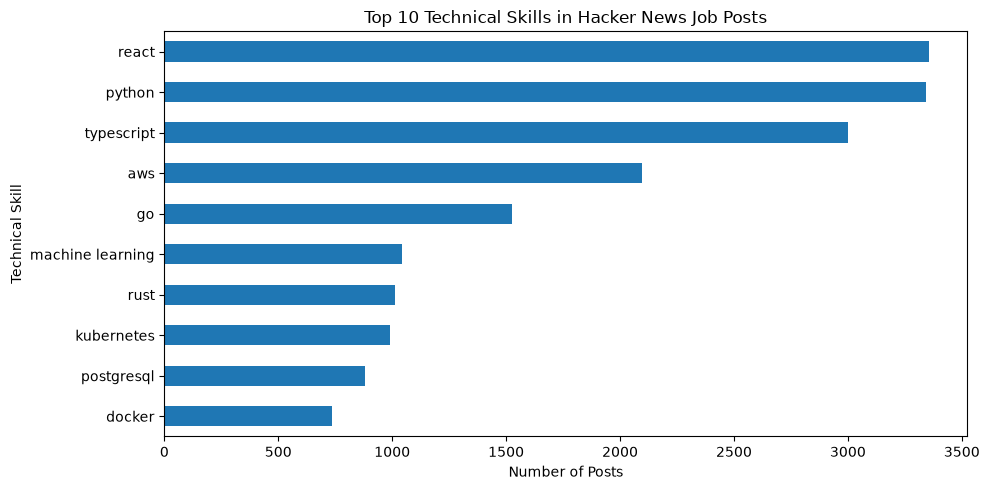

In [3]:
import matplotlib.pyplot as plt
from collections import Counter
counts = Counter()
for value in analysis_df["skills"].dropna():
    counts.update(skill.strip() for skill in value.split(",") if skill.strip())
top = pd.Series(dict(counts.most_common(10))).sort_values()
ax = top.plot(kind="barh", figsize=(10, 5))
ax.set_title("Top 10 Technical Skills in Hacker News Job Posts")
ax.set_xlabel("Number of Posts")
ax.set_ylabel("Technical Skill")
plt.tight_layout()
plt.show()

## Hypothesis-driven visualizations — Teresa

 **Source:** [02_visualizations_teresa.ipynb](02_visualizations_teresa.ipynb).

These three analyses usesd pandas, matplotlib, and seaborn: the top 15 technical skills, AI-related skill mentions over time, and five programming-language trends. The code below reproduces the charts directly from `jobs_cleaned.csv`.

**Denominator clarification:** The earlier descriptive overview uses **9,124 likely hiring posts with at least one recognized skill**. These three analyses use **all 14,127 likely hiring posts**, including **5,003 with no recognized skills**, after excluding 1,070 comments flagged as unlikely job posts. This prevents percentages from being conditioned on successful skill extraction. Raw skill counts agree across these populations, but their percentage denominators differ. Each unique posting counts at most once per skill or category.

The data ends on **November 10, 2026**. Annual comparisons are descriptive; a January–October sensitivity check reduces unequal calendar coverage. The categories and results are detailed with each chart.

In [4]:
from pathlib import Path
import hashlib
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display, Markdown

# Locate the dataset from either the repository root or notebooks directory.
DATA_PATH = next((base / 'data/processed/jobs_cleaned.csv'
                  for base in [Path.cwd(), *Path.cwd().parents]
                  if (base / 'data/processed/jobs_cleaned.csv').is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Open this notebook inside the TechSkills repository.')
source_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
raw = pd.read_csv(DATA_PATH)
sns.set_theme(style='whitegrid', context='notebook', font_scale=1.1)
plt.rcParams.update({'figure.dpi': 120, 'axes.titleweight': 'bold'})

## Preparation and analysis population
Inspection identifies `skills` as comma-separated strings (missing entries have no extracted skills), `date` as timestamps with a UTC offset, and `id` as the posting identifier. We parse dates directly rather than trusting the supplied year/month fields.

We retain `is_likely_job == True`, remove duplicate IDs, and restrict valid dates to 2023–2026. This uses the cleaner's existing heuristic to exclude likely discussion comments; it can also exclude genuine ads. Invalid or out-of-window dates are reported and excluded consistently from all charts. Missing skills become empty sets and **remain in denominators**. They mean “no recognized skill,” not necessarily “no technical requirements.”

Skills are normalized for case, whitespace, and explicit aliases, then converted to sets. Membership uses exact tokens, so JavaScript cannot match Java and PostgreSQL is not automatically SQL. We preserve the existing extraction rather than rescan text with substring matching. The upstream cleaner uses a fixed vocabulary and word boundaries; it can miss variants such as “machine-learning” and mistake ordinary uses of “go” for the language.

In [5]:
required = {'id', 'date', 'skills', 'is_likely_job'}
assert required <= set(raw.columns), f'Missing expected columns: {required - set(raw.columns)}'
assert raw['id'].notna().all(), 'Missing posting IDs require review.'
flag = raw['is_likely_job'].astype('string').str.strip().str.casefold()
assert flag.isin(['true', 'false']).all(), 'Unexpected job flag values require review.'
jobs = raw.loc[flag.eq('true')].copy()
duplicate_ids = int(jobs['id'].duplicated().sum())
jobs = jobs.drop_duplicates('id').copy()
jobs['posted_at'] = pd.to_datetime(jobs['date'], errors='coerce', utc=True)
invalid_dates = int(jobs['posted_at'].isna().sum())
in_window = jobs['posted_at'].dt.year.between(2023, 2026)
outside_window = int((jobs['posted_at'].notna() & ~in_window).sum())
jobs = jobs.loc[in_window].reset_index(drop=True)
jobs['posting_year'] = jobs['posted_at'].dt.year

ALIASES = {'js': 'javascript', 'javascript (js)': 'javascript',
           'golang': 'go', 'py torch': 'pytorch', 'tensor flow': 'tensorflow',
           'machine-learning': 'machine learning', 'ml': 'machine learning',
           'llms': 'llm', 'large language model': 'llm',
           'large language models': 'llm', 'genai': 'generative ai'}
def parse_skills(value):
    # The inspected CSV stores comma-delimited strings, not Python list literals.
    if pd.isna(value):
        return frozenset()
    tokens = [re.sub(r'\s+', ' ', item.strip().casefold()) for item in value.split(',')]
    return frozenset(ALIASES.get(token, token) for token in tokens if token)

jobs['skill_set'] = jobs['skills'].map(parse_skills)
vocabulary = sorted(set().union(*jobs['skill_set']))
# A boolean row/column matrix guarantees at most one mention per posting per skill.
mentions = pd.DataFrame({skill: jobs['skill_set'].map(lambda values: skill in values)
                         for skill in vocabulary}, index=jobs.index)
years = sorted(jobs['posting_year'].unique())
annual_n = jobs.groupby('posting_year').size().reindex(years)
annual_counts = mentions.groupby(jobs['posting_year']).sum().reindex(years)
annual_pct = annual_counts.div(annual_n, axis=0).mul(100)
coverage = jobs.groupby('posting_year').agg(
    postings=('id', 'size'), first_post=('posted_at', 'min'), last_post=('posted_at', 'max'),
    observed_months=('posted_at', lambda x: ', '.join(map(str, sorted(x.dt.month.unique())))),
    no_extracted_skills=('skill_set', lambda x: x.map(len).eq(0).sum()))
coverage['no_extracted_skills_pct'] = coverage['no_extracted_skills'].div(coverage['postings']).mul(100)
display(pd.Series({'input_rows': len(raw), 'excluded_unlikely_job': int(flag.eq('false').sum()),
                   'duplicate_job_ids_removed': duplicate_ids, 'invalid_dates_removed': invalid_dates,
                   'outside_2023_2026_removed': outside_window, 'analysis_postings': len(jobs)}))
display(coverage)
print('Observed skill vocabulary:', ', '.join(vocabulary))
print('Analysis date range:', jobs['posted_at'].min(), 'to', jobs['posted_at'].max())
print('CSV SHA-256:', source_hash)
assert jobs['id'].is_unique and len(jobs) > 0
assert (mentions.sum(axis=1) == jobs['skill_set'].map(len)).all()
assert annual_pct.ge(0).all().all() and annual_pct.le(100).all().all()
assert 'java' not in parse_skills('JavaScript')
assert parse_skills('Python, python, PYTHON') == frozenset({'python'})

input_rows                   15197
excluded_unlikely_job         1070
duplicate_job_ids_removed        0
invalid_dates_removed            0
outside_2023_2026_removed        0
analysis_postings            14127
dtype: int64

,postings,first_post,last_post,observed_months,no_extracted_skills,no_extracted_skills_pct
posting_year,,,,,,
2023,3888,2023-01-02 16:01:37+00:00,2023-12-15 17:23:07+00:00,"1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12",1324,34.053498
2024,3659,2024-01-02 16:02:48+00:00,2024-12-16 15:02:12+00:00,"1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12",1344,36.731347
2025,3730,2025-01-02 16:00:38+00:00,2025-12-15 21:28:05+00:00,"1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12",1307,35.040214
2026,2850,2026-01-02 16:04:13+00:00,2026-11-10 15:11:57+00:00,"1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11",1028,36.070175


Observed skill vocabulary: aws, c++, docker, flutter, generative ai, git, go, java, javascript, kubernetes, linux, llm, machine learning, node.js, postgresql, python, pytorch, rails, react, ruby, rust, scala, sql, swift, tensorflow, typescript
Analysis date range: 2023-01-02 16:01:37+00:00 to 2026-11-10 15:11:57+00:00
CSV SHA-256: 82d6940191e47e0a94511d41f6bff30796318e525ea6672bf1f280a2133f2dd8


## Visualization 1: Most frequently mentioned technical skills
**Hypothesis:** Python, JavaScript, and SQL are among the most frequently mentioned technical skills. We operationalize “among” as appearing in the top 15.

**Methodology:** Sum the boolean skill columns over all eligible postings, sort by descending count (alphabetically for ties), and plot the top 15 horizontally. Labels show unique posting counts, not the number of times words appear. Every posting has equal weight.

**Visualization:**

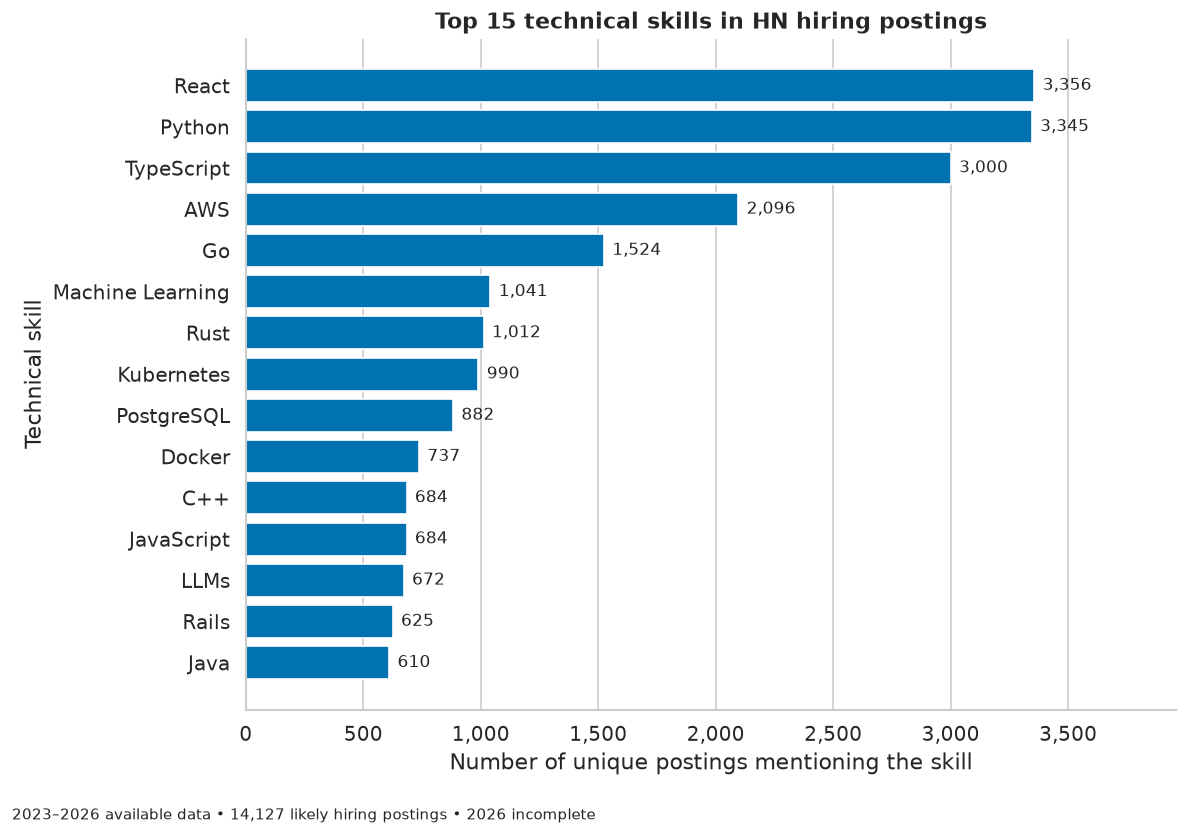

,skill,postings,percentage
rank,,,
1,react,3356,23.76
2,python,3345,23.68
3,typescript,3000,21.24
4,aws,2096,14.84
5,go,1524,10.79
6,machine learning,1041,7.37
7,rust,1012,7.16
8,kubernetes,990,7.01
9,postgresql,882,6.24


In [6]:
LABELS = {'python': 'Python', 'java': 'Java', 'javascript': 'JavaScript', 'go': 'Go',
          'rust': 'Rust', 'sql': 'SQL', 'aws': 'AWS', 'llm': 'LLMs', 'pytorch': 'PyTorch',
          'tensorflow': 'TensorFlow', 'node.js': 'Node.js', 'c++': 'C++',
          'postgresql': 'PostgreSQL', 'typescript': 'TypeScript', 'git': 'Git'}
def label(skill):
    return LABELS.get(skill, skill.title())

ranking = mentions.sum().rename('postings').rename_axis('skill').reset_index()
ranking = ranking.sort_values(['postings', 'skill'], ascending=[False, True]).reset_index(drop=True)
ranking['rank'] = np.arange(1, len(ranking) + 1)
ranking['percentage'] = ranking['postings'].div(len(jobs)).mul(100)
top15 = ranking.head(15)
fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(top15['skill'].map(label), top15['postings'], color=sns.color_palette('colorblind')[0])
ax.invert_yaxis()
ax.bar_label(bars, labels=[f'{n:,}' for n in top15['postings']], padding=5, fontsize=10)
ax.set_xlim(0, top15['postings'].max() * 1.18)
ax.set(title='Top 15 technical skills in HN hiring postings',
       xlabel='Number of unique postings mentioning the skill', ylabel='Technical skill')
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
ax.grid(axis='y', visible=False)
sns.despine(ax=ax)
fig.text(0.01, 0.01, f'2023–2026 available data • {len(jobs):,} likely hiring postings • 2026 incomplete', fontsize=9)
fig.tight_layout(rect=(0, .035, 1, 1))
plt.show()
display(top15.set_index('rank').round(2))

In [7]:
leaders = '; '.join(f"{label(r.skill)}: {r.postings:,} postings ({r.percentage:.2f}%)" for r in ranking.head(3).itertuples())
target_rows = ranking.set_index('skill').reindex(['python', 'javascript', 'sql'])
target_text = '; '.join(f"{label(skill)} ranks #{int(row['rank'])} ({int(row['postings']):,}; {row['percentage']:.2f}%)" for skill, row in target_rows.iterrows())
supported = target_rows['rank'].le(15).all()
display(Markdown(f"**Findings:** The leading skills are {leaders}. {target_text}.\n\n"
                 f"**Conclusion:** The hypothesis is {'supported' if supported else 'not fully supported'} under the top-15 definition.\n\n"
                 "**Limitations:** Counts pool years with unequal sample sizes and may include repeated company advertisements in different months. The fixed extraction vocabulary misses skills and variants; ambiguous tokens can produce false positives. Missing skills remain in the population. These are mention counts, not vacancies or hiring outcomes."))

**Findings:** The leading skills are React: 3,356 postings (23.76%); Python: 3,345 postings (23.68%); TypeScript: 3,000 postings (21.24%). Python ranks #2 (3,345; 23.68%); JavaScript ranks #12 (684; 4.84%); SQL ranks #19 (553; 3.91%).

**Conclusion:** The hypothesis is not fully supported under the top-15 definition.

**Limitations:** Counts pool years with unequal sample sizes and may include repeated company advertisements in different months. The fixed extraction vocabulary misses skills and variants; ambiguous tokens can produce false positives. Missing skills remain in the population. These are mention counts, not vacancies or hiring outcomes.

**Findings snapshot — supplied CSV, executed November 11, 2026.** The calculated output above refreshes on rerun; this narrative records the submitted analysis.

**Findings:** The leading skills are React: 3,356 postings (23.76%); Python: 3,345 postings (23.68%); TypeScript: 3,000 postings (21.24%). Python ranks #2 (3,345; 23.68%); JavaScript ranks #12 (684; 4.84%); SQL ranks #19 (553; 3.91%).

**Conclusion:** The hypothesis is not fully supported under the top-15 definition.

**Limitations:** Counts pool years with unequal sample sizes and may include repeated company advertisements in different months. The fixed extraction vocabulary misses skills and variants; ambiguous tokens can produce false positives. Missing skills remain in the population. These are mention counts, not vacancies or hiring outcomes.

## Visualization 2: AI-related skills versus programming skills
**Hypothesis:** The share of postings mentioning AI-related skills increased between 2023 and 2026.

**Methodology:** The AI group comprises the observed tokens **machine learning, PyTorch, TensorFlow, LLMs, and generative AI**. The comparison group comprises **Python, Java, and JavaScript**. A posting counts once per category if it mentions any category member. Categories overlap: Python is often used in AI, so this is a comparison of skill groups, not AI versus non-AI jobs. Annual percentages divide each category's posting count by **all eligible postings that year**, including those without extracted skills. The tables show denominators and individual AI skills as well.

We also compare January–October across years, excluding November and December to reduce the unequal-coverage problem from data ending in November 2026. This sensitivity check cannot prove each month is fully collected.

**Visualization:**

AI-related category: Machine Learning, PyTorch, TensorFlow, LLMs, Generative Ai
Programming comparison: Python, Java, JavaScript


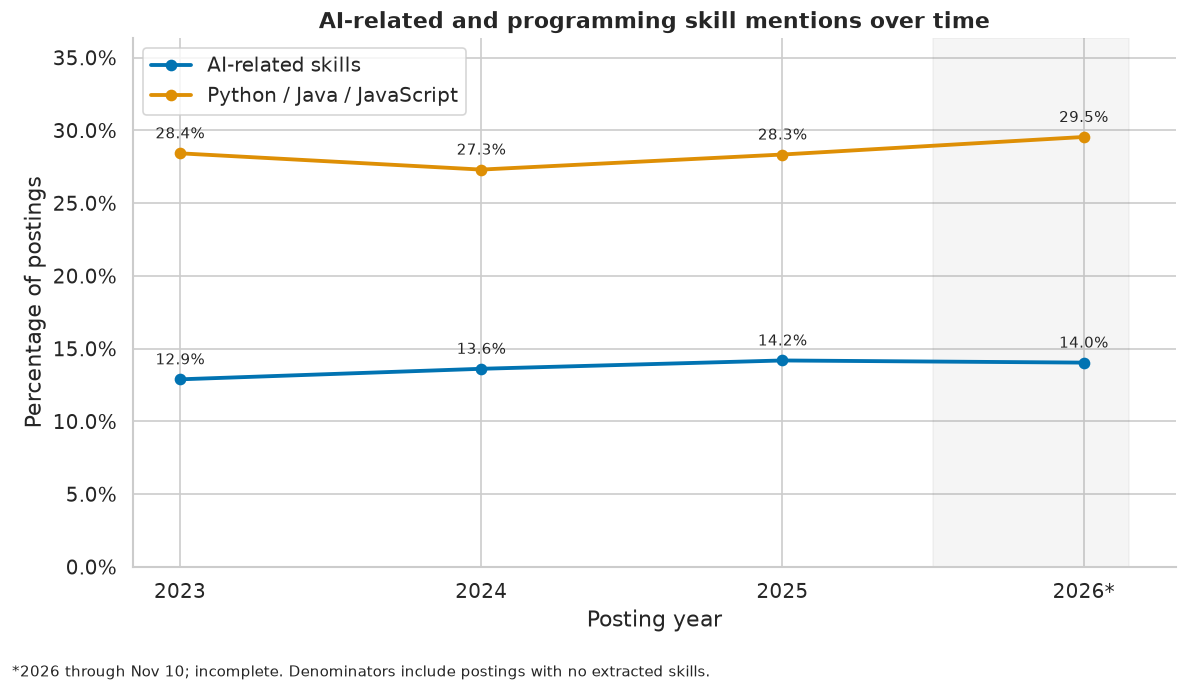

,all_postings,AI-related skills count,Python / Java / JavaScript count,AI-related skills %,Python / Java / JavaScript %
posting_year,,,,,
2023,3888,501,1105,12.89,28.42
2024,3659,498,999,13.61,27.30
2025,3730,529,1057,14.18,28.34
2026,2850,400,842,14.04,29.54


,Machine Learning,PyTorch,TensorFlow,LLMs,Generative Ai
posting_year,,,,,
2023,10.03,1.13,1.03,1.41,1.23
2024,8.42,1.45,0.66,3.83,1.91
2025,5.98,2.20,0.40,6.43,1.50
2026,4.21,2.28,0.74,8.32,0.81


January–October sensitivity check (percent):


,all_postings,AI-related skills,Python / Java / JavaScript
posting_year,,,
2023,3256,12.87,29.18
2024,3059,13.70,27.82
2025,3041,14.21,28.54
2026,2650,14.00,29.66


In [8]:
ai_candidates = ['machine learning', 'pytorch', 'tensorflow', 'llm', 'generative ai']
traditional_candidates = ['python', 'java', 'javascript']
ai_skills = [s for s in ai_candidates if s in vocabulary]
traditional_skills = [s for s in traditional_candidates if s in vocabulary]
assert ai_skills and traditional_skills
print('AI-related category:', ', '.join(map(label, ai_skills)))
print('Programming comparison:', ', '.join(map(label, traditional_skills)))
categories = pd.DataFrame({'AI-related skills': mentions[ai_skills].any(axis=1),
                            'Python / Java / JavaScript': mentions[traditional_skills].any(axis=1)})
category_counts = categories.groupby(jobs['posting_year']).sum().reindex(years)
category_pct = category_counts.div(annual_n, axis=0).mul(100)

def trend_axes(title):
    fig, ax = plt.subplots(figsize=(10, 5.8))
    ax.set(title=title, xlabel='Posting year', ylabel='Percentage of postings')
    ax.set_xticks(years, [f'{year}*' if year == 2026 else str(year) for year in years])
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
    if 2026 in years:
        ax.axvspan(2025.5, 2026.15, color='grey', alpha=.08)
    fig.text(.01, .01, '*2026 through Nov 10; incomplete. Denominators include postings with no extracted skills.', fontsize=9)
    return fig, ax

fig, ax = trend_axes('AI-related and programming skill mentions over time')
for color, column in zip(sns.color_palette('colorblind'), category_pct.columns):
    ax.plot(years, category_pct[column], marker='o', linewidth=2.3, label=column, color=color)
    for year, value in category_pct[column].items():
        ax.annotate(f'{value:.1f}%', (year, value), xytext=(0, 9), textcoords='offset points', ha='center', fontsize=9)
ax.set_ylim(0, category_pct.max().max() * 1.23)
ax.legend(loc='upper left')
sns.despine(ax=ax)
fig.tight_layout(rect=(0, .04, 1, 1))
plt.show()
display(pd.concat([annual_n.rename('all_postings'), category_counts.add_suffix(' count'),
                   category_pct.add_suffix(' %')], axis=1).round(2))
display(annual_pct[ai_skills].rename(columns=label).round(2))

# Equal calendar-month coverage: January–October only in every available year.
matched_mask = jobs['posted_at'].dt.month.le(10)
matched_n = jobs.loc[matched_mask].groupby('posting_year').size().reindex(years)
matched_category_pct = categories.loc[matched_mask].groupby(jobs.loc[matched_mask, 'posting_year']).sum().div(matched_n, axis=0).mul(100)
print('January–October sensitivity check (percent):')
display(pd.concat([matched_n.rename('all_postings'), matched_category_pct], axis=1).round(2))

In [9]:
first, last = years[0], years[-1]
ai_first, ai_last = category_pct.loc[first, 'AI-related skills'], category_pct.loc[last, 'AI-related skills']
ai_change = ai_last - ai_first
traditional_change = category_pct.iloc[-1, 1] - category_pct.iloc[0, 1]
matched_change = matched_category_pct.loc[last, 'AI-related skills'] - matched_category_pct.loc[first, 'AI-related skills']
display(Markdown(f"**Findings:** AI-related mentions changed from {ai_first:.2f}% in {first} to {ai_last:.2f}% in {last}, a {ai_change:+.2f} percentage-point change. "
                 f"The programming comparison changed from {category_pct.iloc[0, 1]:.2f}% to {category_pct.iloc[-1, 1]:.2f}% ({traditional_change:+.2f} points). "
                 f"For January–October alone, AI-related mentions changed from {matched_category_pct.loc[first, 'AI-related skills']:.2f}% to {matched_category_pct.loc[last, 'AI-related skills']:.2f}% ({matched_change:+.2f} points).\n\n"
                 f"**Conclusion:** The directional hypothesis is {'supported descriptively' if ai_change > 0 else 'not supported'} by the available full-period endpoints; "
                 f"the matched-month check {'also shows an increase' if matched_change > 0 else 'does not show an increase'}. This does not establish statistical significance or continuous year-by-year growth.\n\n"
                 "**Limitations:** 2026 is incomplete, November is partial, and sample composition may change. Categories overlap and differ in size. Fixed-vocabulary extraction can undercount AI terms and new technologies. Mention shares describe this HN sample, not the entire labor market or completed hires."))

**Findings:** AI-related mentions changed from 12.89% in 2023 to 14.04% in 2026, a +1.15 percentage-point change. The programming comparison changed from 28.42% to 29.54% (+1.12 points). For January–October alone, AI-related mentions changed from 12.87% to 14.00% (+1.13 points).

**Conclusion:** The directional hypothesis is supported descriptively by the available full-period endpoints; the matched-month check also shows an increase. This does not establish statistical significance or continuous year-by-year growth.

**Limitations:** 2026 is incomplete, November is partial, and sample composition may change. Categories overlap and differ in size. Fixed-vocabulary extraction can undercount AI terms and new technologies. Mention shares describe this HN sample, not the entire labor market or completed hires.

**Findings snapshot — supplied CSV, executed November 11, 2026.** The calculated output above refreshes on rerun; this narrative records the submitted analysis.

**Findings:** AI-related mentions changed from 12.89% in 2023 to 14.04% in 2026, a +1.15 percentage-point change. The programming comparison changed from 28.42% to 29.54% (+1.12 points). For January–October alone, AI-related mentions changed from 12.87% to 14.00% (+1.13 points).

**Conclusion:** The directional hypothesis is supported descriptively by the available full-period endpoints; the matched-month check also shows an increase. This does not establish statistical significance or continuous year-by-year growth.

**Limitations:** 2026 is incomplete, November is partial, and sample composition may change. Categories overlap and differ in size. Fixed-vocabulary extraction can undercount AI terms and new technologies. Mention shares describe this HN sample, not the entire labor market or completed hires.

## Visualization 3: Programming language trends
**Hypothesis:** Some programming languages become more common in postings while others remain stable or decline.

**Methodology:** For each year, calculate the percentage of all eligible postings containing the exact normalized token for Python, Java, JavaScript, Go, or Rust. Plot one line per language. A posting can count toward several languages. “Increasing” and “decreasing” refer to the first-to-last available year difference; **stable** is defined in advance as an absolute difference below **1 percentage point**. This is a descriptive threshold, not a significance test. Report annual values and the January–October sensitivity check.

**Visualization:**

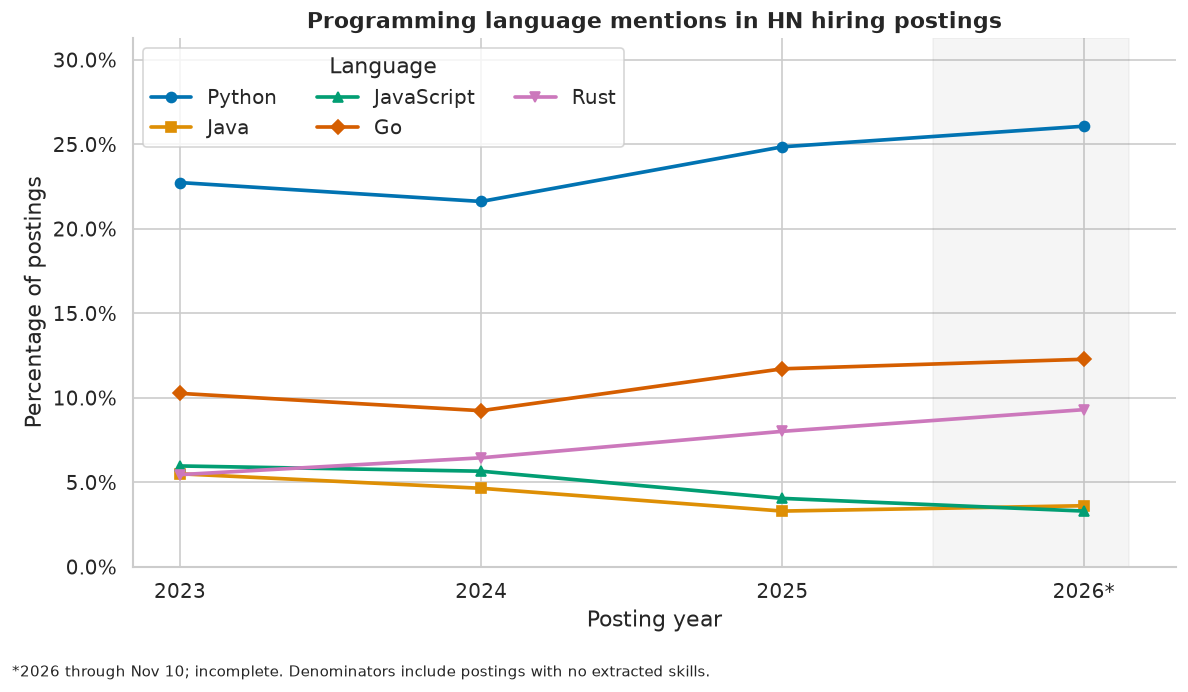

,Python,Java,JavaScript,Go,Rust
posting_year,,,,,
2023,22.74,5.50,5.97,10.26,5.45
2024,21.62,4.65,5.66,9.24,6.45
2025,24.85,3.30,4.05,11.72,8.02
2026,26.07,3.61,3.30,12.28,9.30


,2023 %,2026 %,change_pp,direction,Jan–Oct change_pp,Jan–Oct direction
Python,22.74,26.07,3.33,increasing,2.95,increasing
Java,5.50,3.61,-1.89,decreasing,-2.14,decreasing
JavaScript,5.97,3.30,-2.67,decreasing,-2.85,decreasing
Go,10.26,12.28,2.02,increasing,1.92,increasing
Rust,5.45,9.30,3.85,increasing,3.63,increasing


In [10]:
languages = ['python', 'java', 'javascript', 'go', 'rust']
missing_languages = sorted(set(languages) - set(vocabulary))
if missing_languages:
    print('No recognized mentions for:', missing_languages)
language_pct = annual_pct.reindex(columns=languages, fill_value=0)
fig, ax = trend_axes('Programming language mentions in HN hiring postings')
for skill, color, marker in zip(languages, sns.color_palette('colorblind', 5), ['o', 's', '^', 'D', 'v']):
    ax.plot(years, language_pct[skill], label=label(skill), marker=marker, linewidth=2.2, color=color)
ax.set_ylim(0, language_pct.max().max() * 1.2)
ax.legend(title='Language', ncol=3, loc='upper left')
sns.despine(ax=ax)
fig.tight_layout(rect=(0, .04, 1, 1))
plt.show()
display(language_pct.rename(columns=label).round(2))
matched_language_pct = mentions.loc[matched_mask].groupby(jobs.loc[matched_mask, 'posting_year']).sum().div(matched_n, axis=0).mul(100).reindex(columns=languages, fill_value=0)
STABLE_THRESHOLD_PP = 1.0
def classify(change):
    if abs(change) < STABLE_THRESHOLD_PP:
        return 'stable'
    return 'increasing' if change > 0 else 'decreasing'

language_summary = pd.DataFrame({f'{first} %': language_pct.loc[first], f'{last} %': language_pct.loc[last]})
language_summary['change_pp'] = language_pct.loc[last] - language_pct.loc[first]
language_summary['direction'] = language_summary['change_pp'].map(classify)
language_summary['Jan–Oct change_pp'] = matched_language_pct.loc[last] - matched_language_pct.loc[first]
language_summary['Jan–Oct direction'] = language_summary['Jan–Oct change_pp'].map(classify)
display(language_summary.rename(index=label).round(2))

In [11]:
language_lines = '\n'.join(f"- **{label(skill)}:** {row[f'{first} %']:.2f}% → {row[f'{last} %']:.2f}% ({row['change_pp']:+.2f} percentage points), **{row['direction']}**; January–October change {row['Jan–Oct change_pp']:+.2f} points ({row['Jan–Oct direction']})." for skill, row in language_summary.iterrows())
mixed = language_summary['direction'].eq('increasing').any() and language_summary['direction'].isin(['stable', 'decreasing']).any()
display(Markdown(f"**Findings:** Endpoint changes from {first} to {last}:\n\n{language_lines}\n\n"
                 f"**Conclusion:** The hypothesis is {'supported descriptively' if mixed else 'not supported under the stated threshold'}: "
                 "the classifications above describe the observed mix of trends. Annual paths may fluctuate even when endpoint differences indicate growth or decline.\n\n"
                 "**Limitations:** The 1-point stability threshold is a presentation convention, not an inferential result. Go may be overcounted because the upstream extractor also recognizes the ordinary word 'go'; these results therefore concern extracted tokens and require manual validation before making strong claims about Go demand. Java and JavaScript are kept distinct. Repeat ads, changing HN participation, missing extracted skills, and incomplete 2026 coverage limit generalization."))

**Findings:** Endpoint changes from 2023 to 2026:

- **Python:** 22.74% → 26.07% (+3.33 percentage points), **increasing**; January–October change +2.95 points (increasing).
- **Java:** 5.50% → 3.61% (-1.89 percentage points), **decreasing**; January–October change -2.14 points (decreasing).
- **JavaScript:** 5.97% → 3.30% (-2.67 percentage points), **decreasing**; January–October change -2.85 points (decreasing).
- **Go:** 10.26% → 12.28% (+2.02 percentage points), **increasing**; January–October change +1.92 points (increasing).
- **Rust:** 5.45% → 9.30% (+3.85 percentage points), **increasing**; January–October change +3.63 points (increasing).

**Conclusion:** The hypothesis is supported descriptively: the classifications above describe the observed mix of trends. Annual paths may fluctuate even when endpoint differences indicate growth or decline.

**Limitations:** The 1-point stability threshold is a presentation convention, not an inferential result. Go may be overcounted because the upstream extractor also recognizes the ordinary word 'go'; these results therefore concern extracted tokens and require manual validation before making strong claims about Go demand. Java and JavaScript are kept distinct. Repeat ads, changing HN participation, missing extracted skills, and incomplete 2026 coverage limit generalization.

**Findings snapshot — supplied CSV, executed November 11, 2026.** The calculated output above refreshes on rerun; this narrative records the submitted analysis.

**Findings:** Endpoint changes from 2023 to 2026:

- **Python:** 22.74% → 26.07% (+3.33 percentage points), **increasing**; January–October change +2.95 points (increasing).
- **Java:** 5.50% → 3.61% (-1.89 percentage points), **decreasing**; January–October change -2.14 points (decreasing).
- **JavaScript:** 5.97% → 3.30% (-2.67 percentage points), **decreasing**; January–October change -2.85 points (decreasing).
- **Go:** 10.26% → 12.28% (+2.02 percentage points), **increasing**; January–October change +1.92 points (increasing).
- **Rust:** 5.45% → 9.30% (+3.85 percentage points), **increasing**; January–October change +3.63 points (increasing).

**Conclusion:** The hypothesis is supported descriptively: the classifications above describe the observed mix of trends. Annual paths may fluctuate even when endpoint differences indicate growth or decline.

**Limitations:** The 1-point stability threshold is a presentation convention, not an inferential result. Go may be overcounted because the upstream extractor also recognizes the ordinary word 'go'; these results therefore concern extracted tokens and require manual validation before making strong claims about Go demand. Java and JavaScript are kept distinct. Repeat ads, changing HN participation, missing extracted skills, and incomplete 2026 coverage limit generalization.

In [12]:
assert annual_n.sum() == len(jobs)
assert (category_counts.le(annual_n, axis=0)).all().all()
assert language_pct.ge(0).all().all() and language_pct.le(100).all().all()
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == source_hash, 'Source CSV changed during execution.'
print('Verification passed: unique posting IDs, valid percentages, consistent denominators, exact skill matching, and unchanged source CSV.')

Verification passed: unique posting IDs, valid percentages, consistent denominators, exact skill matching, and unchanged source CSV.


## Machine learning and baselines

**Team to add:** Two different models with clearly defined targets, features, train/test splits, baseline comparisons, metrics, and interpretations. Validate seniority labels before relying on them for classification.

## Reflection

Inconsistent job-post formatting and heuristic extraction are key risks. Filtering for posts with recognized skills also changes the analysis population. The dataset is still useful for exploring trends within the Hacker News hiring community if we communicate these limits and validate important fields.

**Teresa’s findings and reflection:** React, Python, and TypeScript led extracted skill mentions. Python and JavaScript appeared in the top 15, but SQL ranked nineteenth, so the first hypothesis was not fully supported. AI-related mentions increased modestly from 12.89% in 2023 to 14.04% in 2026, with a similar increase when comparing January–October. Python, Go, and Rust increased in mention share while Java and JavaScript declined; the matched-month comparison preserved these directions.

The main analytical challenges were choosing consistent denominators, counting each skill once per posting, keeping Java distinct from JavaScript, and interpreting incomplete 2026 data. The existing extractor can confuse ordinary uses of “go” with the Go language, so that trend needs manual validation. These analyses describe skill mentions within this sample, not proven changes in hiring demand across the labor market.

**Completed contribution:** Teresa’s three visualizations, interpretations, and limitations are integrated into this report. **Team to add:** Two remaining hypothesis-driven charts, modeling results and reflections, and confirmation of overall schedule status.

## Next steps

Before the November 13 progress report, merge the remaining team analyses, rerun the combined notebook, and export the required PDF. Teresa’s three visualizations are now included; manually review ambiguous Go mentions and retain explicit denominator and partial-year notes in the final presentation. For the final project, validate extracted labels, improve parsing as needed, and interpret trends with consistent denominators.

**Team to confirm:** Owners and dates for remaining work.